# 00 — Bitcoin block times

**Goal:** download the last ~2,000 Bitcoin blocks from the public mempool.space API and look at the
time between consecutive blocks. Bitcoin is designed to produce one block every **10 minutes on average**.
How close is reality to that design, and how much does it vary?

**Data source:** mempool.space public REST API (Bitcoin mainnet). Timestamps are the `timestamp` field
of each block header, in Unix **seconds**, interpreted as **UTC**.

Run the cells **one at a time, top to bottom**. Write your predictions first.

## Predictions (written before running)

1. Will the mean inter-block time be above, below, or about equal to 10 minutes? By how much?
   - Answer:
2. What will the longest gap between two consecutive blocks be (in minutes)?
   - Answer:
3. Will there be any negative differences (a block with an earlier timestamp than the block before it)?
   - Answer:
4. What shape will the histogram of inter-block times have?
   - Answer:
5. Will the prev-hash chain check pass (every block points to the block right before it)?
   - Answer:

## 1. Imports and settings

We load the libraries and set the parameters in one place, so they are easy to find and change:
how many blocks we want, how long to pause between API calls, and how many times to retry.
We also locate the repo root so the cache always goes to `data/` (which git ignores),
whether the notebook runs from the repo root or from `notebooks/`.

In [11]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

API_BASE = "https://mempool.space/api"
N_BLOCKS = 2_000        # how many blocks we want (approximately; pages have 15 blocks)
SLEEP_SECONDS = 1.0     # pause after every real API call, to be polite to the server
MAX_RETRIES = 5         # how many times to retry after HTTP 429 "Too Many Requests"
TIMEOUT_SECONDS = 30    # give up on a single request after this many seconds

# The repo root is the first folder (going upwards) that contains CLAUDE.md.
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
CACHE_DIR = REPO_ROOT / "data" / "mempool_blocks"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
print("Cache folder:", CACHE_DIR.relative_to(REPO_ROOT))  # relative: no local user path

Cache folder: data\mempool_blocks


## 2. A safe way to call the API

`get_json` downloads one URL and returns its JSON. If the server answers **HTTP 429**
("you are asking too fast"), we wait and try again, doubling the wait each time
(2, 4, 8, 16, 32 seconds). This is called *exponential backoff*. If the server sends a
`Retry-After` header, we respect it instead. Any other error (404, 500, ...) stops the notebook
immediately, so we never silently work with bad data.

In [12]:
def get_json(url):
    """GET a URL and return the parsed JSON. Retry with exponential backoff on HTTP 429."""
    for attempt in range(MAX_RETRIES + 1):
        response = requests.get(url, timeout=TIMEOUT_SECONDS)
        if response.status_code != 429:
            response.raise_for_status()  # any other HTTP error stops here
            return response.json()
        if attempt == MAX_RETRIES:
            break
        retry_after = response.headers.get("Retry-After", "")
        wait = int(retry_after) if retry_after.isdigit() else 2 ** (attempt + 1)
        print(f"HTTP 429 on {url} -> waiting {wait}s (retry {attempt + 1}/{MAX_RETRIES})")
        time.sleep(wait)
    raise RuntimeError(f"Still rate-limited after {MAX_RETRIES} retries: {url}")

## 3. Cache: download once, reuse forever

`cached_get_json` first looks for a saved copy of the response in `data/mempool_blocks/`.
If it exists, it reads the file and makes **no** API call. If not, it downloads, saves the raw JSON,
and then sleeps. This makes re-runs fast, avoids hammering the API, and makes the analysis
**reproducible**: everyone who re-runs it with the same cache gets exactly the same numbers.
We write to a temporary file first and then rename it, so an interrupted download never leaves
a half-written cache file behind.

In [13]:
def cached_get_json(url, cache_file):
    """Return JSON from cache_file if it exists; otherwise download, save, and sleep."""
    if cache_file.exists():
        return json.loads(cache_file.read_text(encoding="utf-8"))
    data = get_json(url)
    tmp_file = cache_file.with_suffix(".tmp")
    tmp_file.write_text(json.dumps(data), encoding="utf-8")
    tmp_file.replace(cache_file)
    time.sleep(SLEEP_SECONDS)
    return data

## 4. Where is the chain right now? (tip height)

The *tip* is the newest block. Its *height* is its position in the chain (block 0 is the first one ever).
We cache the tip too: that **freezes** our sample, so re-runs analyze the same blocks.
To get fresh data later, delete the `data/mempool_blocks/` folder and run again.

In [14]:
tip_height = cached_get_json(f"{API_BASE}/blocks/tip/height", CACHE_DIR / "tip_height.json")
print("Tip height:", tip_height)

Tip height: 975603


## 5. Walk backwards through the chain

`/v1/blocks/:startHeight` returns 15 blocks: `startHeight` and the 14 before it.
We start at the tip, then ask for the page that starts just below the lowest height we got,
and repeat until we have about 2,000 blocks (that is ~134 API calls, roughly 2–3 minutes the
first time; instant afterwards thanks to the cache).

In [15]:
raw_blocks = []
start_height = tip_height
while len(raw_blocks) < N_BLOCKS and start_height >= 0:
    page = cached_get_json(
        f"{API_BASE}/v1/blocks/{start_height}",
        CACHE_DIR / f"blocks_{start_height}.json",
    )
    if not page:  # empty answer: nothing more to fetch
        break
    raw_blocks.extend(page)
    start_height = min(block["height"] for block in page) - 1

print(f"Collected {len(raw_blocks)} raw blocks")

Collected 2010 raw blocks


## 6. Keep only the columns we need, in time order

From each block we keep `height`, `id` (the block hash), `previousblockhash` and `timestamp`.
We check for duplicate heights (there should be none), sort from oldest to newest,
and convert the Unix timestamp to a readable date. The unit is **seconds** (`unit="s"`)
and the timezone is **UTC** — getting either wrong would silently shift every date.

In [16]:
df = pd.DataFrame(raw_blocks)[["height", "id", "previousblockhash", "timestamp"]]

n_duplicates = df["height"].duplicated().sum()
print("Duplicate heights:", n_duplicates)
df = df.drop_duplicates(subset="height").sort_values("height").reset_index(drop=True)

df["time_utc"] = pd.to_datetime(df["timestamp"], unit="s", utc=True)

print(f"{len(df)} blocks, heights {df['height'].min()} to {df['height'].max()}")
print(f"From {df['time_utc'].min()} to {df['time_utc'].max()}")
df.head()

Duplicate heights: 0
2010 blocks, heights 973594 to 975603
From 2026-10-28 20:04:00+00:00 to 2026-11-12 21:53:19+00:00


,height,id,previousblockhash,timestamp,time_utc
0,973594,00000000000000000001ce1f5187ab32d628c3a6212757...,00000000000000000001ec933956f6ccf2281f8d6850b2...,1793217840,2026-10-28 20:04:00+00:00
1,973595,0000000000000000000110bba915d08c843ea34e736dc7...,00000000000000000001ce1f5187ab32d628c3a6212757...,1793218943,2026-10-28 20:22:23+00:00
2,973596,000000000000000000014106c34e0ce906cc0aa3314b8c...,0000000000000000000110bba915d08c843ea34e736dc7...,1793219817,2026-10-28 20:36:57+00:00
3,973597,000000000000000000009e11d17475abd6e0e2b750afd6...,000000000000000000014106c34e0ce906cc0aa3314b8c...,1793220137,2026-10-28 20:42:17+00:00
4,973598,000000000000000000015df68194a2866e53d7794164be...,000000000000000000009e11d17475abd6e0e2b750afd6...,1793220711,2026-10-28 20:51:51+00:00


## 7. Verify the chain

A blockchain is a chain because each block stores the hash of the block before it.
If our data is complete and correct, then for every block (except the oldest one we have,
whose parent we did not download):

- heights go up by exactly 1, with no gaps, and
- `previousblockhash` equals the `id` of the block at `height - 1`.

This is a data-quality check: if it fails, something went wrong in the download.

In [17]:
heights_contiguous = (df["height"].diff().dropna() == 1).all()

df["parent_id_in_data"] = df["id"].shift(1)  # id of the row above = block at height - 1
checkable = df.iloc[1:]                      # the oldest block has no parent in our data
broken = checkable[checkable["previousblockhash"] != checkable["parent_id_in_data"]]

print("Heights contiguous:", heights_contiguous)
print(f"Links checked: {len(checkable)}, broken links: {len(broken)}")
print("CHAIN CHECK:", "PASS" if heights_contiguous and broken.empty else "FAIL")
broken[["height", "id", "previousblockhash", "parent_id_in_data"]]

Heights contiguous: True
Links checked: 2009, broken links: 0
CHAIN CHECK: PASS


,height,id,previousblockhash,parent_id_in_data


## 8. Time between consecutive blocks

For each block, we subtract the timestamp of the previous block and divide by 60 to get minutes.
The oldest block has no previous block, so its value is empty and is dropped.
Then we summarize: mean, median, min, max, and how many differences are negative.

**Note on timestamps:** a block's `timestamp` is written by the miner who found it, not by a
central clock. Consensus rules only require it to be later than the median of the previous 11 blocks
and not too far in the future, so consecutive timestamps can be slightly out of order.
This makes individual gaps (and therefore the min and max) noisy. The **mean**, however, only depends
on the first and last timestamps of the sample (the differences in between cancel out),
so it is robust to that noise.

In [18]:
df["minutes_since_prev"] = df["timestamp"].diff() / 60
gaps = df["minutes_since_prev"].dropna()

summary = pd.Series({
    "count": len(gaps),
    "mean (min)": gaps.mean(),
    "median (min)": gaps.median(),
    "min (min)": gaps.min(),
    "max (min)": gaps.max(),
    "negative values": int((gaps < 0).sum()),
})
print(summary.round(2).to_string())

print("\nBlock after the longest gap:")
df.loc[[gaps.idxmax()], ["height", "time_utc", "minutes_since_prev"]]

count              2009.00
mean (min)           10.81
median (min)          7.43
min (min)            -6.20
max (min)            78.42
negative values      59.00

Block after the longest gap:


,height,time_utc,minutes_since_prev
1083,974677,2026-11-05 14:54:39+00:00,78.416667


## 9. How often is a block slower than 20 minutes?

`gaps > 20` gives `True` for every gap longer than 20 minutes and `False` otherwise.
Python treats `True` as 1 and `False` as 0, so the **mean** of that column is the fraction of
slow blocks; multiplying by 100 turns it into a percentage. *(Added by the repo owner.)*

In [19]:
pct_over_20 = (gaps > 20).mean() * 100
print(f"Blocks that took more than 20 minutes: {pct_over_20:.1f}%")

Blocks that took more than 20 minutes: 15.6%


## 10. Histogram of inter-block times

A histogram counts how many gaps fall into each range of minutes. The dashed line marks the
10-minute design target, the dotted line marks the mean we measured, and the dash-dot line marks
the median *(median line added by the repo owner)*.

**How to read the shape:** finding a block is like a lottery that every miner plays many times per
second, and each try has the same tiny chance of winning, no matter how long it has been since the
last block (the process has *no memory*). Waiting times of that kind follow an **exponential
distribution**: many short gaps, few long ones, and a long tail to the right. That tail pulls the
mean above the median.

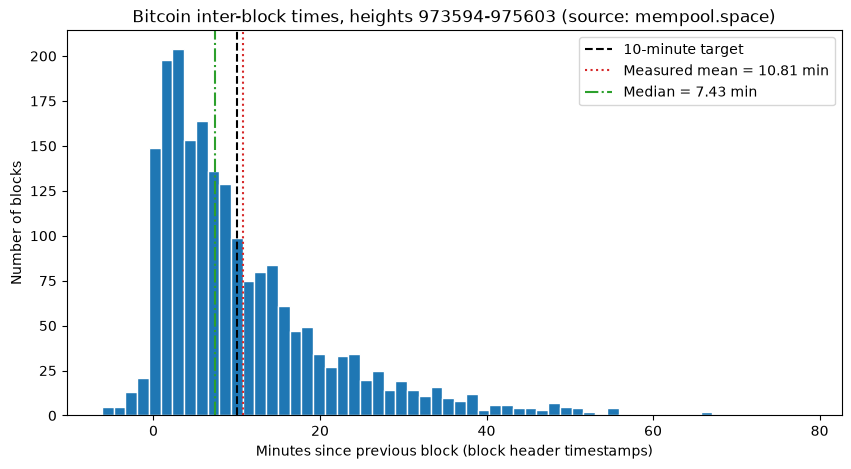

In [20]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(gaps, bins=60, edgecolor="white")
ax.axvline(10, color="black", linestyle="--", label="10-minute target")
ax.axvline(gaps.mean(), color="tab:red", linestyle=":", label=f"Measured mean = {gaps.mean():.2f} min")
ax.axvline(gaps.median(), color="tab:green", linestyle="-.", label=f"Median = {gaps.median():.2f} min")
ax.set_xlabel("Minutes since previous block (block header timestamps)")
ax.set_ylabel("Number of blocks")
ax.set_title(
    f"Bitcoin inter-block times, heights {df['height'].min()}-{df['height'].max()} "
    "(source: mempool.space)"
)
ax.legend()
plt.show()

## Results vs predictions